In [223]:
import pandas as pd
import numpy as np
import missingno as msno
import miceforest as mf
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from lightgbm import sklearn
from scipy.stats import zscore
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import OrdinalEncoder
from pyampute.exploration.mcar_statistical_tests import MCARTest

In [214]:
train_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0)

In [215]:
# Saving this for later
address = train_df["BlockAddress"]
date = train_df["event_dt"]

In [216]:
# Dropping driver license state variable, officerassignment variable, stopdescription, VehicleModel and VehicleMake variable
train_df = train_df.drop(["SubjectDriverLicState", "OfficerAssignment", "StopDescription", "NOPD_Item", "VehicleModel", "VehicleMake", "BlockAddress", "event_dt"], axis=1)

In [217]:
# Recoding Eyecolor variable; for this and the rest (categorical data binning), pick labels that are either NaN or make up at least 1% of all values
eye_freq = train_df["SubjectEyeColor"].value_counts(normalize=True)

eye_labels = eye_freq[eye_freq >= 0.01].index.tolist()

train_df["SubjectEyeColor"] = np.where(train_df["SubjectEyeColor"].isin(eye_labels) | train_df["SubjectEyeColor"].isna(), train_df["SubjectEyeColor"], "Other")

# Recoding Hair variable
hair_freq = train_df["SubjectHairColor"].value_counts(normalize=True)

hair_labels = hair_freq[hair_freq >= 0.01].index.tolist()

train_df["SubjectHairColor"] = np.where(train_df["SubjectHairColor"].isin(hair_labels) | train_df["SubjectHairColor"].isna(), train_df["SubjectHairColor"], "Other")

# Recoding Vehicle Style variable
vehiclestyle_freq = train_df["VehicleStyle"].value_counts(normalize=True)

vehiclestyle_labels = vehiclestyle_freq[vehiclestyle_freq >= 0.01].index.tolist()

train_df["VehicleStyle"] = np.where(train_df["VehicleStyle"].isin(vehiclestyle_labels) | train_df["VehicleStyle"].isna(), train_df["VehicleStyle"], "Other")

# Recoding Vehicle Color variable
vehiclecolor_freq = train_df["VehicleColor"].value_counts(normalize=True)

vehiclecolor_labels = vehiclecolor_freq[vehiclecolor_freq >= 0.01].index.tolist()

train_df["VehicleColor"] = np.where(train_df["VehicleColor"].isin(vehiclecolor_labels) | train_df["VehicleColor"].isna(), train_df["VehicleColor"], "Other")

C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\missingno\missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


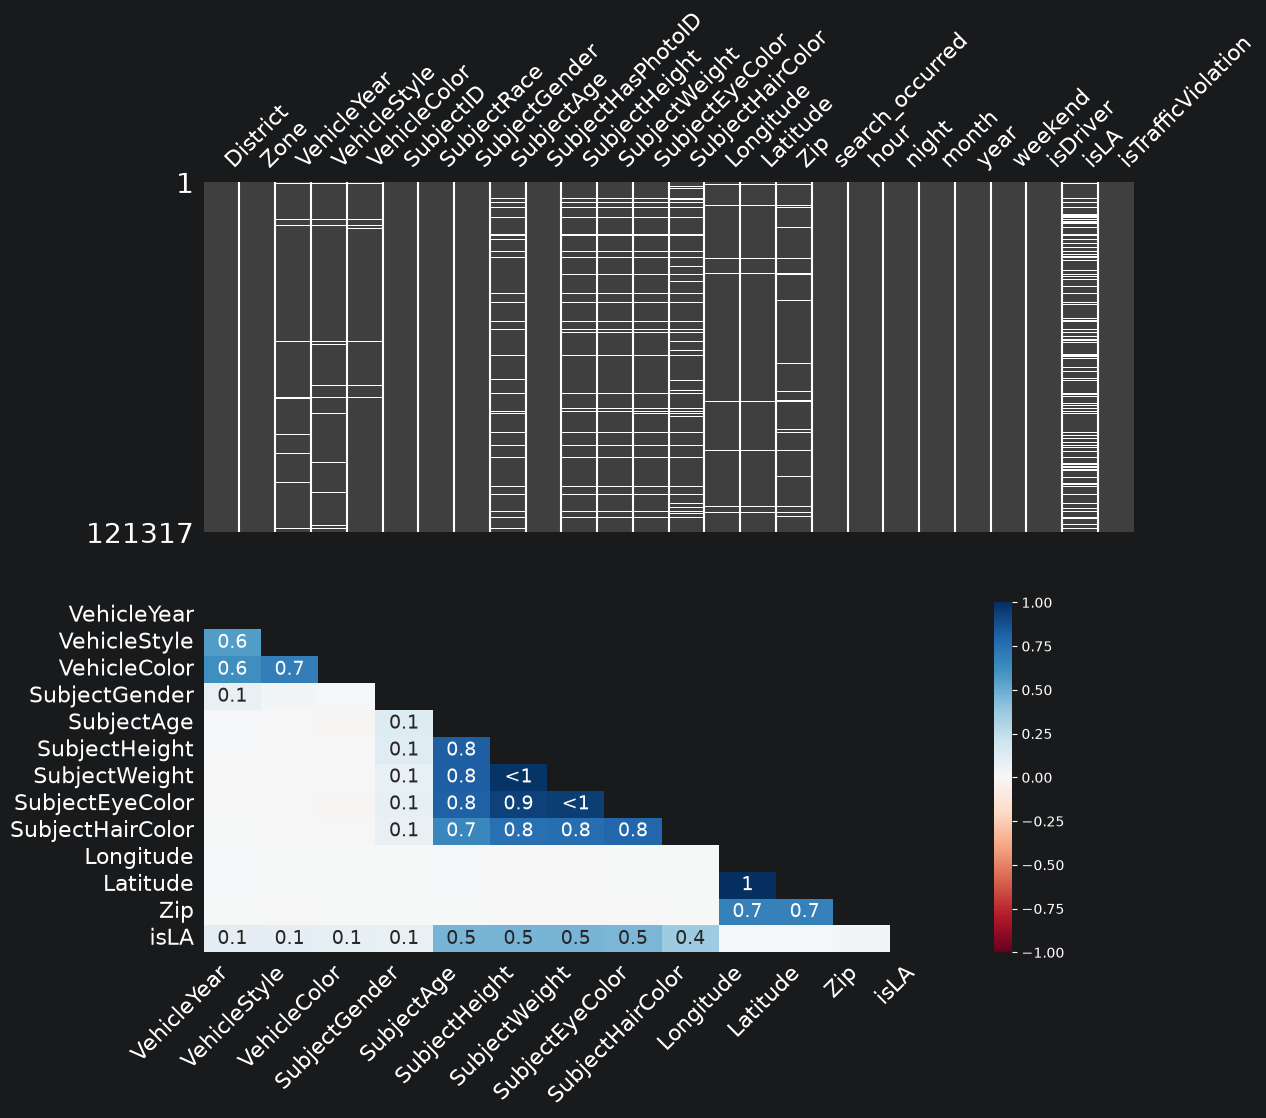

In [218]:
# Visualize missingness pattern in training data
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
msno.matrix(train_df, ax=ax[0])
msno.heatmap(train_df, ax=ax[1])
plt.show()

In [219]:
# Potential outlier columns: VehicleYear, SubjectAge, SubjectHeight
# Impute impossible or highly implausible values as NaN
train_df["VehicleYear"] = np.where((train_df["VehicleYear"] == 1900) | (train_df["VehicleYear"] >= 2028), np.nan, train_df["VehicleYear"])

train_df["SubjectAge"] = np.where((train_df["SubjectAge"] < 0) | (train_df["SubjectAge"] > 119), np.nan, train_df["SubjectAge"])

train_df["SubjectHeight"] = np.where((train_df["SubjectHeight"] <= 20) | (train_df["SubjectHeight"] >= 100), np.nan, train_df["SubjectHeight"])

train_df["SubjectWeight"] = np.where((train_df["SubjectWeight"] <= 10) | (train_df["SubjectWeight"] >= 800), np.nan, train_df["SubjectWeight"])

In [234]:
# Examine implausible values
#train_df[(train_df["SubjectAge"] <= 5) | (train_df["SubjectAge"] >= 95) |
         #(train_df["SubjectWeight"] <= 45) | (train_df["SubjectWeight"] >= 700) |
         #(train_df["SubjectHeight"] <= 40) | (train_df["SubjectHeight"] >= 85)]
#train_df[(train_df["SubjectWeight"] <= 45) | (train_df["SubjectWeight"] >= 700)]
# What if we assume for adults, two digit weights are actually 3 digits (data misentry) ex: if an adult has weight 20.0, it was a misentry and it was actually 200

In [180]:
# Ordinal encoding to run MICE imputation
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)

# Defining categorical columns
cat_cols = ["VehicleStyle", "VehicleColor", "SubjectRace", "SubjectEyeColor", "SubjectHairColor", "Zip", "Zone"]

# Drop outcome variable
train_df_enc = train_df.copy()
search_col = train_df_enc["search_occurred"]
train_df_enc = train_df_enc.drop(["search_occurred"], axis=1)

# Ordinal encoding categorical columns, converts ZIP code to string as well
train_df_enc[cat_cols] = encoder.fit_transform(train_df[cat_cols].astype(str))

# Ensure that nan are mapped to na instead of being treated as an actual category
train_df_enc[cat_cols] = train_df_enc[cat_cols].mask(train_df_enc[cat_cols].isna())

# Random forest imputation
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=10, random_state=10), max_iter=10, random_state=10)

train_df_imputed = pd.DataFrame(imputer.fit_transform(train_df_enc), columns = train_df_enc.columns)

# Round imputations into discrete values
train_df_imputed[cat_cols] = train_df_imputed[cat_cols].round()

# Encode back to original labels
train_df_imputed_final = train_df_imputed.copy()
train_df_imputed_final[cat_cols] = encoder.inverse_transform(train_df_imputed[cat_cols])

In [204]:
# Return back to original index
train_df_imputed_final.index = train_df.index

# Return outcome variable, address, stopdate
train_df_imputed_final["search_occurred"] = search_col

train_df_imputed_final["BlockAddress"] = address

train_df_imputed_final["StopDate"] = date

In [205]:
train_df_imputed_final

,District,Zone,VehicleYear,VehicleStyle,VehicleColor,SubjectID,SubjectRace,SubjectGender,SubjectAge,SubjectHasPhotoID,...,night,month,year,weekend,isDriver,isLA,isTrafficViolation,search_occurred,BlockAddress,StopDate
FieldInterviewID,,,,,,,,,,,,,,,,,,,,,
542115,3.0,D,2014.0,FOUR DOOR,BLUE,621847.0,BLACK,0.0,22.0,0.0,...,1.0,8.0,2020.0,0.0,1.0,1.0,0.0,1,Paris Ave & Westbrook Dr,2020-08-18 22:43:00
667644,5.0,K,2007.0,SPORTS UTILITY,BLACK,761029.0,BLACK,0.0,57.0,0.0,...,1.0,4.0,2025.0,0.0,1.0,1.0,1.0,0,St Bernard Av & N Broad St,2025-04-18 21:59:00
617735,4.0,D,2022.0,SPORTS UTILITY,GRAY,705410.0,UNKNOWN,0.0,25.0,0.0,...,1.0,7.0,2023.0,1.0,1.0,0.0,1.0,0,Holiday Dr & General De Gaulle Dr,2023-07-08 04:08:00
482625,3.0,U,2005.0,TWO DOOR,WHITE,549929.0,BLACK,1.0,19.0,0.0,...,1.0,11.0,2018.0,0.0,0.0,1.0,1.0,0,Chef Menteur Hwy & Press Dr,2018-11-20 20:28:00
452319,6.0,M,2011.0,MINIVAN,BLUE,514827.0,BLACK,0.0,29.0,0.0,...,1.0,5.0,2018.0,0.0,1.0,1.0,1.0,0,S Broad St & Erato St,2018-05-22 00:12:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
524702,7.0,C,2009.0,SPORTS UTILITY,SILVER,600525.0,BLACK,1.0,32.0,0.0,...,1.0,10.0,2019.0,0.0,1.0,0.0,0.0,0,Stemway Dr & Ransom St,2019-10-07 20:44:00
677968,3.0,E,2015.0,SPORTS UTILITY,TAN,772166.0,BLACK,1.0,45.0,0.0,...,1.0,7.0,2025.0,1.0,1.0,1.0,1.0,0,Harrison Av & Catina St,2025-07-13 20:33:00
643239,6.0,H,2007.0,SPORTS UTILITY,WHITE,732907.0,BLACK,1.0,42.0,0.0,...,0.0,6.0,2024.0,0.0,1.0,1.0,0.0,1,Martin Luther King Jr Blvd & S Liberty St,2024-06-05 15:15:00


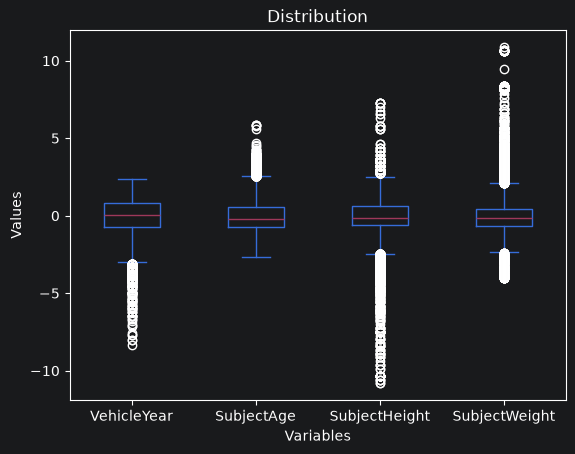

In [206]:
# Boxplots
target_df = train_df_imputed_final[["VehicleYear", "SubjectAge", "SubjectHeight", "SubjectWeight"]]

target_df = target_df.apply(zscore)

ax = target_df.plot(kind="box", title="Distribution")
plt.ylabel("Values")
plt.xlabel("Variables")
plt.show()

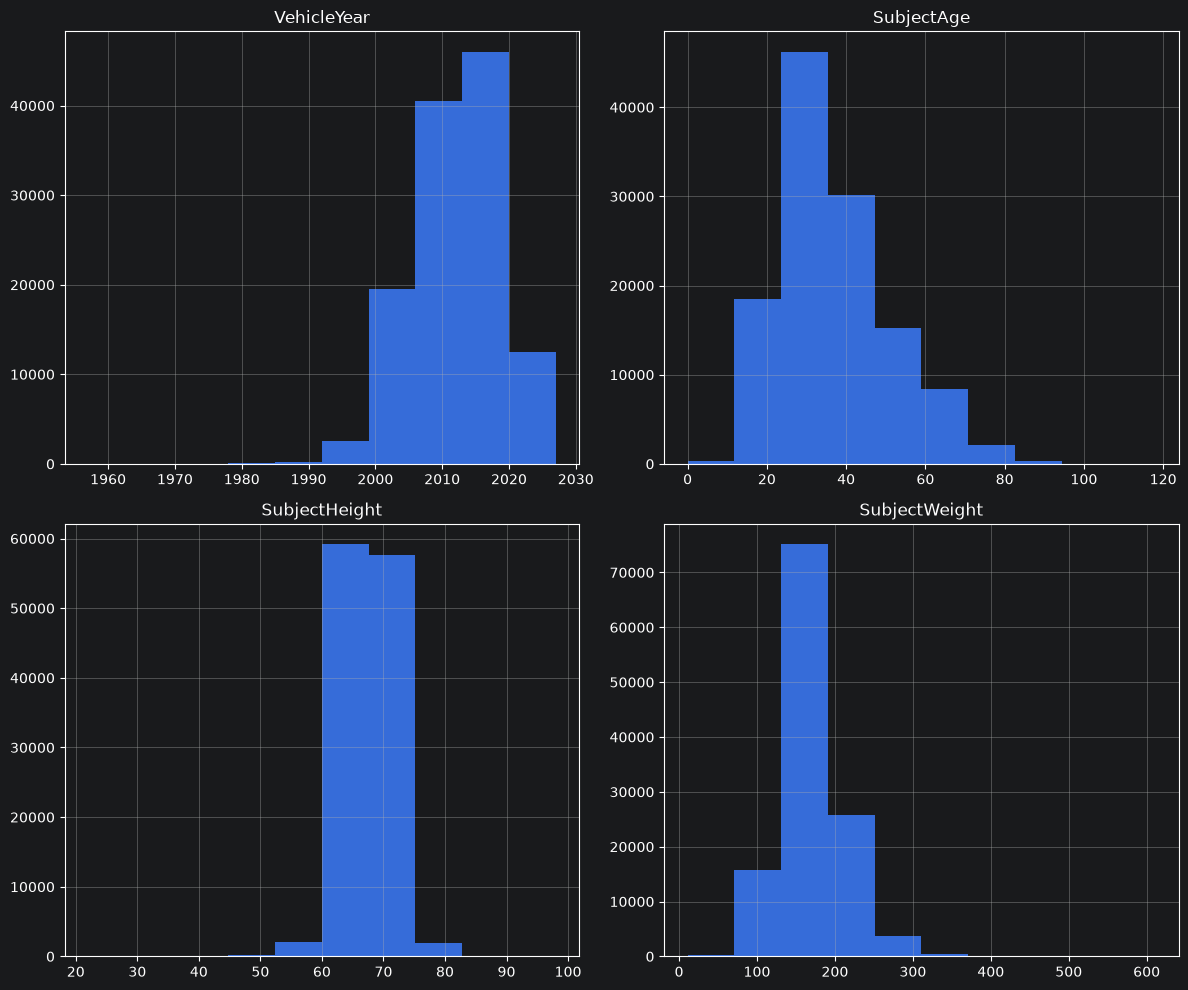

In [207]:
# Histograms
target_df = train_df_imputed_final[["VehicleYear", "SubjectAge", "SubjectHeight", "SubjectWeight"]]

target_df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

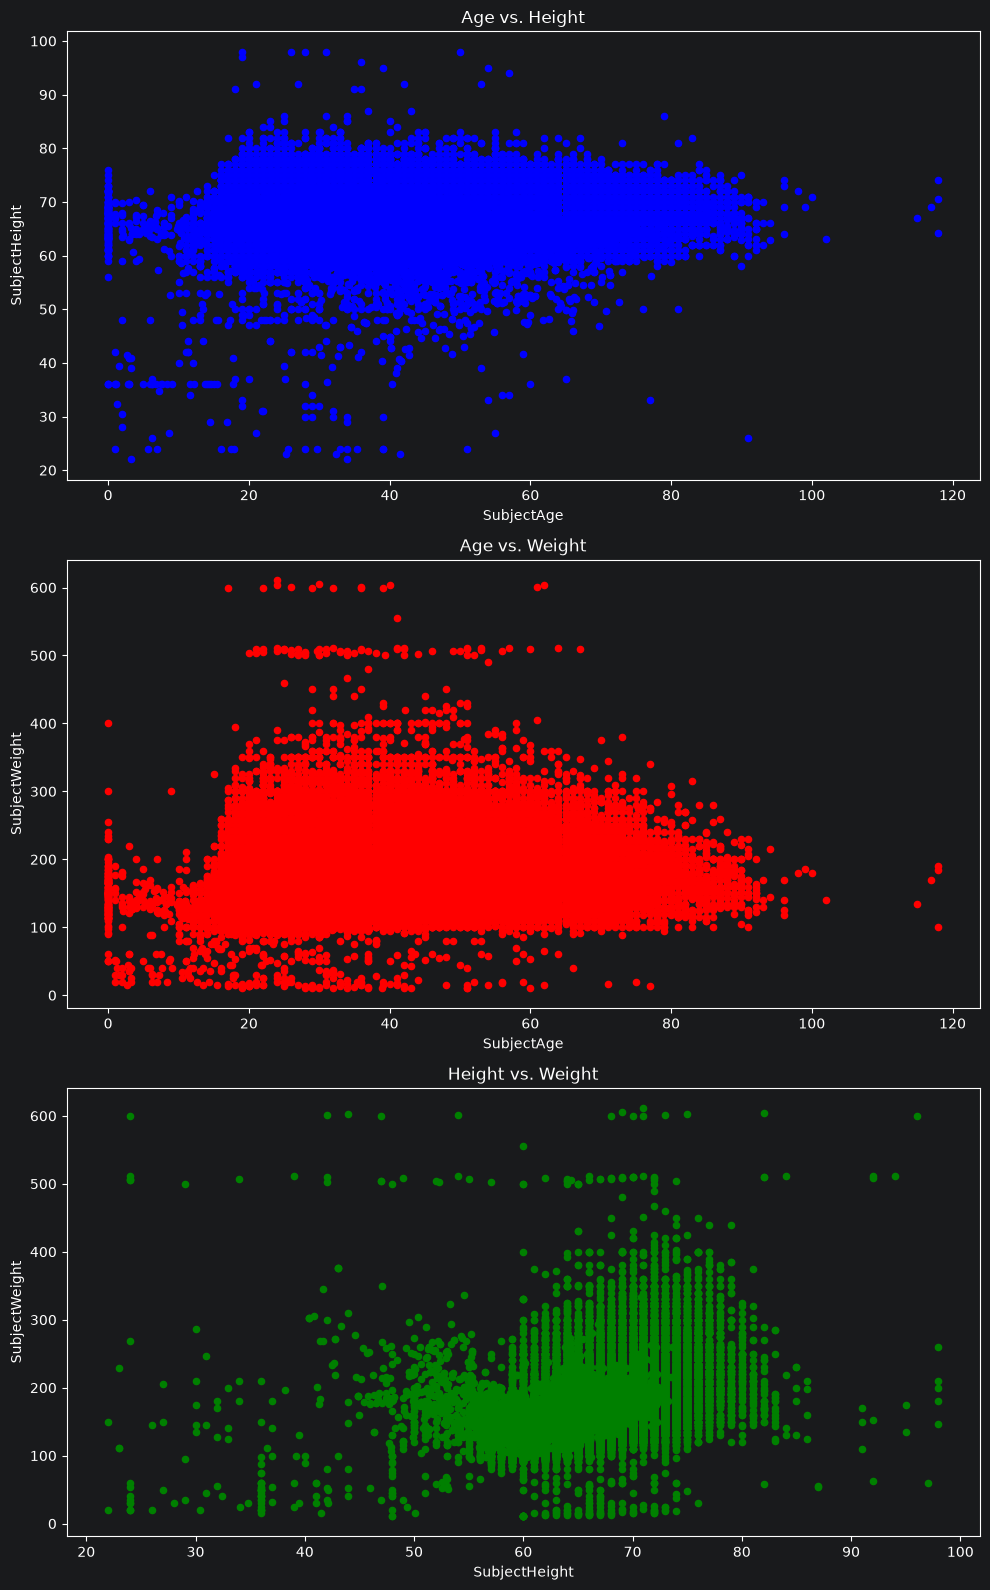

In [212]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 16))

train_df_imputed_final.plot.scatter(x="SubjectAge", y="SubjectHeight", ax=axes[0], color="blue", title="Age vs. Height", )
train_df_imputed_final.plot.scatter(x="SubjectAge", y="SubjectWeight", ax=axes[1], color="red", title="Age vs. Weight")
train_df_imputed_final.plot.scatter(x="SubjectHeight", y="SubjectWeight", ax=axes[2], color="green", title="Height vs. Weight")

plt.tight_layout()
plt.show()

In [235]:
train_df_imputed_final.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train_imputed.csv", index=False)